## 13 — Development-Derived Threshold Analysis

### Methodology & Deployment Simulation

To prevent target leakage and accurately mimic a real-world clinical deployment pipeline, threshold determination and evaluation are strictly partitioned:

#### 1. Threshold Selection (Development Phase Only)
* **Strategy:** Optimal probability decision thresholds are calculated exclusively using predictions from the **train and validation splits**.
* **Youden’s Index:** Optimizes the balance between sensitivity and specificity by maximizing $\text{Sensitivity} + \text{Specificity} - 1$ ($TPF - FPF$).
* **Target Sensitivities ($80\%$ & $90\%$):** Tailored operational points selected to prioritize high recall and minimize false negatives for downstream clinical safety screening.

#### 2. Fixed Threshold Generalization Evaluation
* **Deployment Simulation:** These derived development thresholds are held strictly **unchanged** and applied directly to the independent, held-out **temporal test set**.
* **Objective:** Measures true out-of-time model generalizability and robust real-world performance without data leakage.

In [4]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Setup and Environment Configuration

We import required data audit tools, configuration parameters, and utilities.

In [2]:
from pathlib import Path
import yaml
import pandas as pd
from icare_risk.evaluation.thresholds import threshold_analysis

# Load configuration
CONFIG_PATH = Path('../src/icare_risk/config/icare/analysis.yaml')
with CONFIG_PATH.open() as f:
    config = yaml.safe_load(f)

# Load predictions and map target labels
prediction_path = Path(config['outputs']['prediction_directory']) / 'admission_predictions.parquet'
predictions = pd.read_parquet(prediction_path)
target = config['columns']['target']
prediction_columns = [c for c in predictions.columns if c.endswith('_prob')]

predictions[target] = predictions[target].map({
    **{str(v): 1 for v in config['target_mapping']['positive_values']},
    **{str(v): 0 for v in config['target_mapping']['negative_values']},
}).fillna(pd.to_numeric(predictions[target], errors='coerce'))
predictions = predictions[predictions[target].isin([0, 1])].copy()

# Run threshold analysis
selected, test_results = threshold_analysis(
    predictions, target, prediction_columns,
    target_sensitivities=(0.80, 0.90),
)
display(selected.head(10))
display(test_results.head(10))

# Save results to disk
output_dir = Path(config['outputs']['metrics_directory'])
output_dir.mkdir(parents=True, exist_ok=True)
selected.to_csv(output_dir / 'development_thresholds.csv', index=False)
test_results.to_csv(output_dir / 'fixed_threshold_test_results.csv', index=False)

print(f'Successfully computed thresholds and saved artifacts to {output_dir}')

,model,prediction_column,threshold_name,threshold
0,lr_kim_components,lr_kim_components_prob,youden,0.538944
1,lr_kim_components,lr_kim_components_prob,sensitivity_0.80,0.495108
2,lr_kim_components,lr_kim_components_prob,sensitivity_0.90,0.495108
3,lr_all_score_values,lr_all_score_values_prob,youden,0.494899
4,lr_all_score_values,lr_all_score_values_prob,sensitivity_0.80,0.493421
5,lr_all_score_values,lr_all_score_values_prob,sensitivity_0.90,0.491942
6,lr_clinical_baseline,lr_clinical_baseline_prob,youden,0.485316
7,lr_clinical_baseline,lr_clinical_baseline_prob,sensitivity_0.80,0.475780
8,lr_clinical_baseline,lr_clinical_baseline_prob,sensitivity_0.90,0.460309
9,xgb_kim_components,xgb_kim_components_prob,youden,0.221844


,model,prediction_column,threshold_name,threshold,n,events,tp,tn,fp,fn,sensitivity,specificity,ppv,npv,predicted_positive_rate
0,lr_kim_components,lr_kim_components_prob,youden,0.538944,2483,493,56,1771,219,437,0.113590,0.889950,0.203636,0.802083,0.110753
1,lr_kim_components,lr_kim_components_prob,sensitivity_0.80,0.495108,2483,493,491,2,1988,2,0.995943,0.001005,0.198064,0.500000,0.998389
2,lr_kim_components,lr_kim_components_prob,sensitivity_0.90,0.495108,2483,493,491,2,1988,2,0.995943,0.001005,0.198064,0.500000,0.998389
3,lr_all_score_values,lr_all_score_values_prob,youden,0.494899,2483,493,327,700,1290,166,0.663286,0.351759,0.202226,0.808314,0.651228
4,lr_all_score_values,lr_all_score_values_prob,sensitivity_0.80,0.493421,2483,493,459,140,1850,34,0.931034,0.070352,0.198787,0.804598,0.929923
5,lr_all_score_values,lr_all_score_values_prob,sensitivity_0.90,0.491942,2483,493,491,2,1988,2,0.995943,0.001005,0.198064,0.500000,0.998389
6,lr_clinical_baseline,lr_clinical_baseline_prob,youden,0.485316,2483,493,329,731,1259,164,0.667343,0.367337,0.207179,0.816760,0.639549
7,lr_clinical_baseline,lr_clinical_baseline_prob,sensitivity_0.80,0.475780,2483,493,375,523,1467,118,0.760649,0.262814,0.203583,0.815913,0.741845
8,lr_clinical_baseline,lr_clinical_baseline_prob,sensitivity_0.90,0.460309,2483,493,432,306,1684,61,0.876268,0.153769,0.204159,0.833787,0.852195
9,xgb_kim_components,xgb_kim_components_prob,youden,0.221844,2483,493,56,1771,219,437,0.113590,0.889950,0.203636,0.802083,0.110753


Successfully computed thresholds and saved artifacts to results/metrics


### 2. Receiver Operating Characteristic (ROC) & Operating Points

The ROC curves below illustrate the trade-off between the True Positive Rate (Sensitivity) and False Positive Rate ($1 - \text{Specificity}$) across the primary model architectures during development.

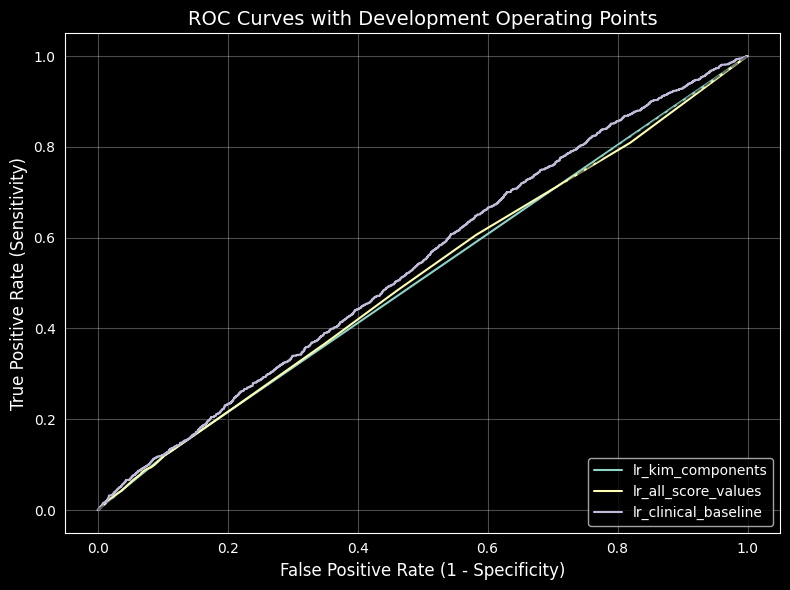

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))
development = predictions[predictions['split'].isin(['train', 'validation'])]

for col in prediction_columns[:3]:  # Plot top models for clarity
    model_name = col.removesuffix('_prob')
    y_true = development[target]
    y_prob = development[col]

    fpr, tpr, thresholds = roc_curve(y_true, y_prob)
    plt.plot(fpr, tpr, label=f'{model_name}')

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
plt.title('ROC Curves with Development Operating Points', fontsize=14)
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 3. Held-Out Test Performance Summary

The summary table below loads the saved `.csv` artifacts from disk, merges development thresholds with fixed-threshold test results, and presents a styled breakdown of out-of-time generalization metrics.

In [11]:
import pandas as pd

# Load saved metrics
dev_thresholds = pd.read_csv('./results/metrics/development_thresholds.csv')
test_results = pd.read_csv('./results/metrics/fixed_threshold_test_results.csv')

# 5. Automatically create and display a clean summary table
summary_table = pd.merge(
    test_results,
    selected[['model', 'prediction_column', 'threshold_name', 'threshold']],
    on=['model', 'prediction_column', 'threshold_name'],
    suffixes=('_eval', '_dev')
)

display_cols = [
    'model', 'threshold_name', 'threshold_dev',
    'sensitivity', 'specificity', 'ppv', 'npv'
]
table_view = summary_table[display_cols].copy()
table_view.columns = ['Model', 'Strategy', 'Threshold', 'Sensitivity', 'Specificity', 'PPV', 'NPV']

styled_table = table_view.style.format({
    'Threshold': '{:.3f}',
    'Sensitivity': '{:.3f}',
    'Specificity': '{:.3f}',
    'PPV': '{:.3f}',
    'NPV': '{:.3f}'
}).background_gradient(subset=['Sensitivity', 'Specificity'], cmap='Blues')

display(styled_table)

,Model,Strategy,Threshold,Sensitivity,Specificity,PPV,NPV
0,lr_kim_components,youden,0.539,0.114,0.890,0.204,0.802
1,lr_kim_components,sensitivity_0.80,0.495,0.996,0.001,0.198,0.500
2,lr_kim_components,sensitivity_0.90,0.495,0.996,0.001,0.198,0.500
3,lr_all_score_values,youden,0.495,0.663,0.352,0.202,0.808
4,lr_all_score_values,sensitivity_0.80,0.493,0.931,0.070,0.199,0.805
5,lr_all_score_values,sensitivity_0.90,0.492,0.996,0.001,0.198,0.500
6,lr_clinical_baseline,youden,0.485,0.667,0.367,0.207,0.817
7,lr_clinical_baseline,sensitivity_0.80,0.476,0.761,0.263,0.204,0.816
8,lr_clinical_baseline,sensitivity_0.90,0.460,0.876,0.154,0.204,0.834
9,xgb_kim_components,youden,0.222,0.114,0.890,0.204,0.802
